In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("ABC Company.xlsx")
print(df.head())

            Name            Team  Number Position  Age               Height  \
0  Avery Bradley  Boston Celtics       0       PG   25  2023-02-06 00:00:00   
1    Jae Crowder  Boston Celtics      99       SF   25  2023-06-06 00:00:00   
2   John Holland  Boston Celtics      30       SG   27  2023-05-06 00:00:00   
3    R.J. Hunter  Boston Celtics      28       SG   22  2023-05-06 00:00:00   
4  Jonas Jerebko  Boston Celtics       8       PF   29  2023-10-06 00:00:00   

   Weight            College     Salary  
0     180              Texas  7730337.0  
1     235          Marquette  6796117.0  
2     205  Boston University        NaN  
3     185      Georgia State  1148640.0  
4     231                NaN  5000000.0  


In [3]:
print(df.shape)
print(df.columns)
print(df.info())
print(df.isnull().sum())

(458, 9)
Index(['Name', 'Team', 'Number', 'Position', 'Age', 'Height', 'Weight',
       'College', 'Salary'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    object 
 1   Team      458 non-null    object 
 2   Number    458 non-null    int64  
 3   Position  458 non-null    object 
 4   Age       458 non-null    int64  
 5   Height    458 non-null    object 
 6   Weight    458 non-null    int64  
 7   College   374 non-null    object 
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), object(5)
memory usage: 32.3+ KB
None
Name         0
Team         0
Number       0
Position     0
Age          0
Height       0
Weight       0
College     84
Salary      11
dtype: int64


In [4]:
df['Height'] = np.random.randint(150, 181, size=len(df))
print(df['Height'].head())

print(df['Height'].min())
print(df['Height'].max())



0    174
1    179
2    178
3    153
4    177
Name: Height, dtype: int32
150
180


In [5]:
team_count = df['Team'].value_counts()
print(team_count)

Team
New Orleans Pelicans      19
Memphis Grizzlies         18
Utah Jazz                 16
New York Knicks           16
Milwaukee Bucks           16
Brooklyn Nets             15
Portland Trail Blazers    15
Oklahoma City Thunder     15
Denver Nuggets            15
Washington Wizards        15
Miami Heat                15
Charlotte Hornets         15
Atlanta Hawks             15
San Antonio Spurs         15
Houston Rockets           15
Boston Celtics            15
Indiana Pacers            15
Detroit Pistons           15
Cleveland Cavaliers       15
Chicago Bulls             15
Sacramento Kings          15
Phoenix Suns              15
Los Angeles Lakers        15
Los Angeles Clippers      15
Golden State Warriors     15
Toronto Raptors           15
Philadelphia 76ers        15
Dallas Mavericks          15
Orlando Magic             14
Minnesota Timberwolves    14
Name: count, dtype: int64


In [6]:
team_count = df['Team'].value_counts()
team_percentage = (team_count / len(df)) * 100
print(team_percentage.round(2))

Team
New Orleans Pelicans      4.15
Memphis Grizzlies         3.93
Utah Jazz                 3.49
New York Knicks           3.49
Milwaukee Bucks           3.49
Brooklyn Nets             3.28
Portland Trail Blazers    3.28
Oklahoma City Thunder     3.28
Denver Nuggets            3.28
Washington Wizards        3.28
Miami Heat                3.28
Charlotte Hornets         3.28
Atlanta Hawks             3.28
San Antonio Spurs         3.28
Houston Rockets           3.28
Boston Celtics            3.28
Indiana Pacers            3.28
Detroit Pistons           3.28
Cleveland Cavaliers       3.28
Chicago Bulls             3.28
Sacramento Kings          3.28
Phoenix Suns              3.28
Los Angeles Lakers        3.28
Los Angeles Clippers      3.28
Golden State Warriors     3.28
Toronto Raptors           3.28
Philadelphia 76ers        3.28
Dallas Mavericks          3.28
Orlando Magic             3.06
Minnesota Timberwolves    3.06
Name: count, dtype: float64


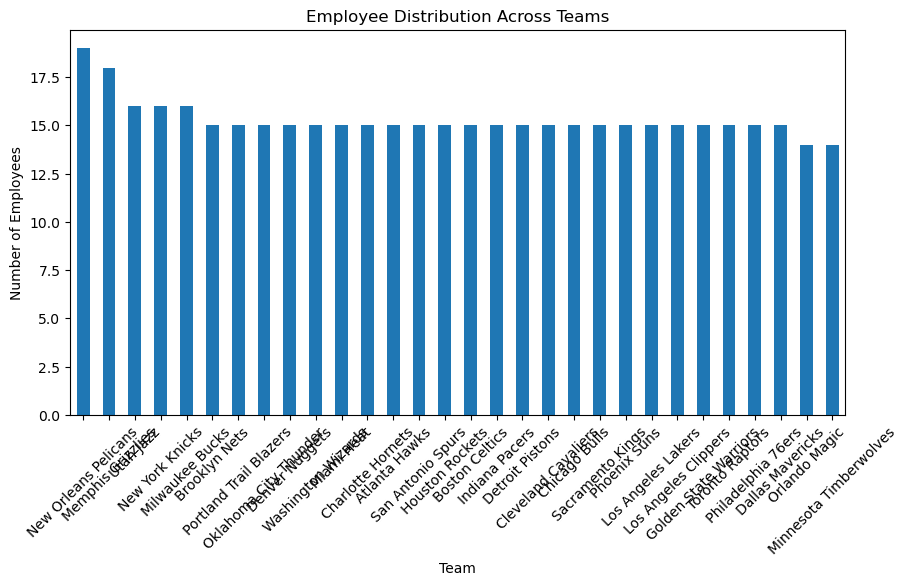

In [7]:
team_count.plot(kind='bar', figsize=(10, 5))

plt.title('Employee Distribution Across Teams')
plt.xlabel('Team')
plt.ylabel('Number of Employees')
plt.xticks(rotation=45)
plt.show()

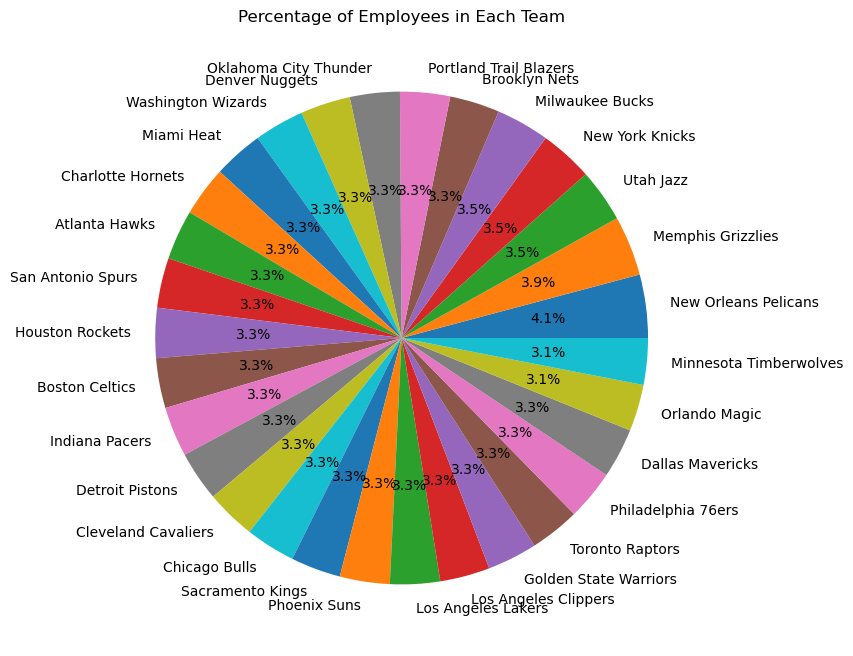

In [8]:
team_count.plot(kind='pie', autopct='%1.1f%%', figsize=(8, 8))

plt.title('Percentage of Employees in Each Team')
plt.ylabel('')
plt.show()

In [9]:
position_count = df['Position'].value_counts()
print(position_count)

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


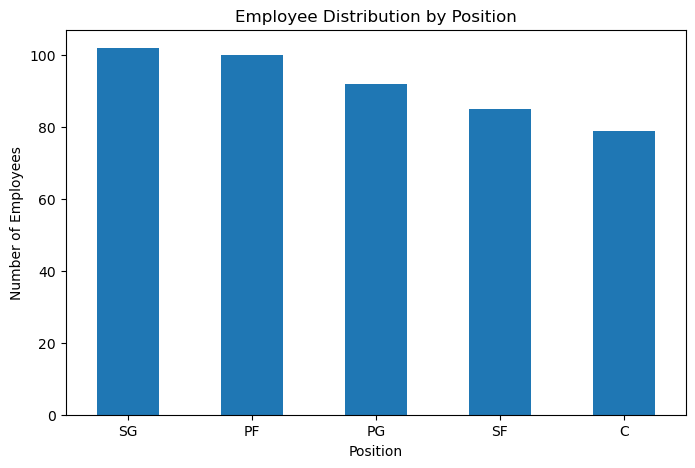

In [10]:
position_count.plot(kind='bar', figsize=(8, 5))

plt.title('Employee Distribution by Position')
plt.xlabel('Position')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)
plt.show()

In [11]:
position_percentage = (position_count / len(df)) * 100
print(position_percentage.round(2))

Position
SG    22.27
PF    21.83
PG    20.09
SF    18.56
C     17.25
Name: count, dtype: float64


In [12]:
bins = [0, 19, 29, 39, 49, 100]
labels = ['Under 20', '20-29', '30-39', '40-49', '50+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)
print(df[['Age', 'Age Group']].head())

   Age Age Group
0   25     20-29
1   25     20-29
2   27     20-29
3   22     20-29
4   29     20-29


In [13]:
age_count = df['Age Group'].value_counts().sort_index()
print(age_count)

Age Group
Under 20      2
20-29       334
30-39       119
40-49         3
50+           0
Name: count, dtype: int64


In [14]:
print("Predominant Age Group:", age_count.idxmax())
print("Number of Employees:", age_count.max())

Predominant Age Group: 20-29
Number of Employees: 334


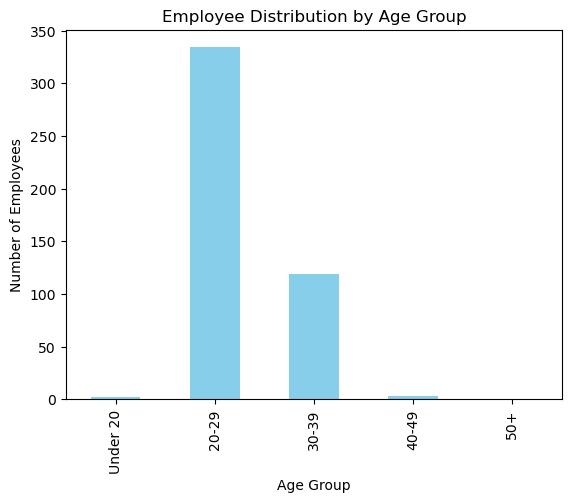

In [15]:
age_count.plot(kind='bar', color='skyblue')

plt.title('Employee Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')
plt.show()

In [16]:
team_salary = df.groupby('Team')['Salary'].sum()
print(team_salary.sort_values(ascending=False))

Team
Cleveland Cavaliers       106988689.0
Los Angeles Clippers       94854640.0
Oklahoma City Thunder      93765298.0
Golden State Warriors      88868997.0
Chicago Bulls              86783378.0
San Antonio Spurs          84442733.0
New Orleans Pelicans       82750774.0
Miami Heat                 82515673.0
Charlotte Hornets          78340920.0
Memphis Grizzlies          76550880.0
Washington Wizards         76328636.0
Houston Rockets            75283021.0
New York Knicks            73303898.0
Atlanta Hawks              72902950.0
Los Angeles Lakers         71770431.0
Sacramento Kings           71683666.0
Dallas Mavericks           71198732.0
Toronto Raptors            71117611.0
Milwaukee Bucks            69603517.0
Detroit Pistons            67168263.0
Indiana Pacers             66751826.0
Utah Jazz                  64007367.0
Phoenix Suns               63445135.0
Orlando Magic              60161470.0
Denver Nuggets             60121930.0
Minnesota Timberwolves     59709697.0
Boston 

In [17]:
print("Team with highest salary expenditure:", team_salary.idxmax())
print("Total salary expenditure:", team_salary.max())

Team with highest salary expenditure: Cleveland Cavaliers
Total salary expenditure: 106988689.0


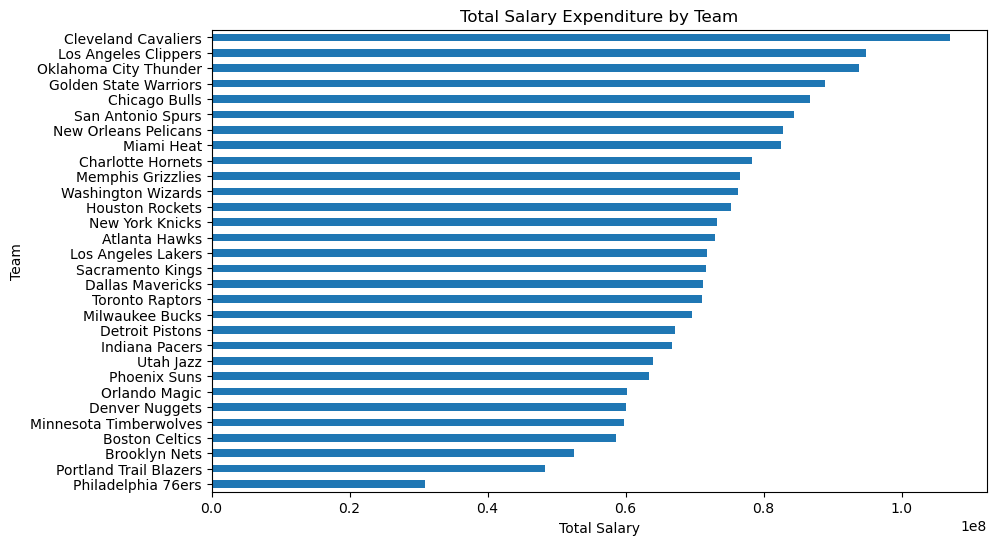

In [18]:
team_salary.sort_values().plot(kind='barh', figsize=(10, 6))

plt.title('Total Salary Expenditure by Team')
plt.xlabel('Total Salary')
plt.ylabel('Team')
plt.show()

In [19]:
position_salary = df.groupby('Position')['Salary'].sum()
print(position_salary.sort_values(ascending=False))

Position
C     466377332.0
PG    446848971.0
PF    442560850.0
SF    408020976.0
SG    396976258.0
Name: Salary, dtype: float64


In [20]:
print("Position with highest salary expenditure:", position_salary.idxmax())
print("Total salary expenditure:", position_salary.max())

Position with highest salary expenditure: C
Total salary expenditure: 466377332.0


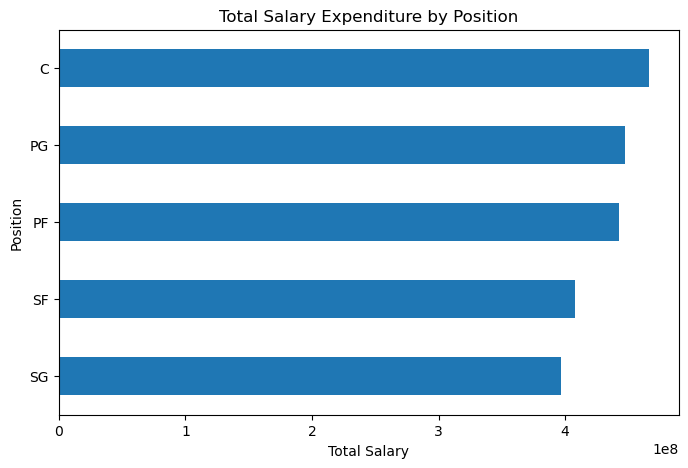

In [21]:
position_salary.sort_values().plot(kind='barh', figsize=(8, 5))

plt.title('Total Salary Expenditure by Position')
plt.xlabel('Total Salary')
plt.ylabel('Position')
plt.show()

In [22]:
correlation = df['Age'].corr(df['Salary'])
print("Correlation between Age and Salary:", correlation)

Correlation between Age and Salary: 0.21400941226570971


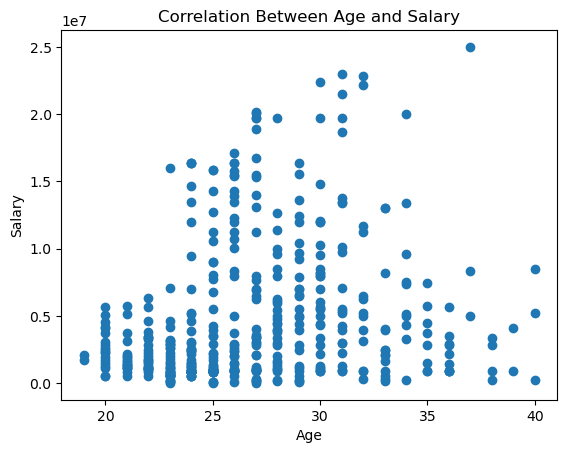

In [23]:
plt.scatter(df['Age'], df['Salary'])

plt.title('Correlation Between Age and Salary')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.show()

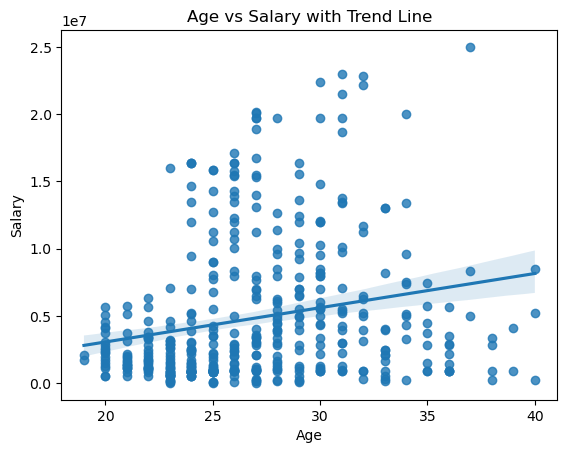

In [24]:
sns.regplot(x='Age', y='Salary', data=df)
plt.title('Age vs Salary with Trend Line')
plt.show()

The analysis of data was conducted in relation to the employees of ABC Company through Python programming language. Initially, I processed data and changed all heights into random data ranging from 150 cm to 180 cm. Then, I identified the distribution of employees among various teams and positions and also the mode in terms of their ages.

In addition, I calculated salary expense per position and also per team. In such a way I examined salary distribution in the firm. At last, I analyzed the relationship between salaries and ages by means of correlation analysis and graphics.

The project allowed me to find out how to use Pandas, NumPy, Matplotlib, and Seaborn libraries for the research of employee data visualization.